# Pilot: does an LLM's confidence predict when it is wrong?

**Question (RQ1 of my proposal):** on medical yes/no/maybe questions, can we tell from the model's own behaviour which answers are likely to be wrong?

**Method**
1. 500 questions from PubMedQA (each has an abstract and a correct answer: yes, no or maybe).
2. An open 7B model answers each question.
3. Two confidence signals:
   - **Token probability:** how much probability the model puts on its chosen answer word.
   - **Agreement (sampling):** ask 10 times with randomness; confidence = share of the 10 answers that agree with the most common one.
4. Check whether low confidence goes with wrong answers (AUROC, accuracy by confidence level, risk vs coverage).

**Before running:** Runtime > Change runtime type > **T4 GPU**. Full run takes roughly 30 to 60 minutes. Results are saved to `pilot_results_V3.csv` as it goes, so if Colab disconnects, just run the cells again and it carries on.

In [ ]:
!pip -q install -U transformers accelerate bitsandbytes datasets scikit-learn

## 1. Settings

In [16]:
MODEL_NAME  = "Qwen/Qwen2.5-7B-Instruct"   # open model, no sign-up needed
N_QUESTIONS = 500        # use 20 first as a quick test, then 500
N_SAMPLES   = 10         # repeated answers per question
TEMPERATURE = 1.0        # randomness for the repeated answers
USE_CONTEXT = True       # True = give the abstract (like RAG with perfect retrieval)
SEED        = 42
OUT_CSV     = "pilot_results_V3.csv"
LABELS      = ["yes", "no", "maybe"]

## 2. Load the questions

In [17]:
from datasets import load_dataset
import random
ds = load_dataset("qiaojin/PubMedQA", "pqa_labeled")["train"]   # 1,000 expert-labelled questions
idx = list(range(len(ds)))
random.Random(SEED).shuffle(idx)
ds = ds.select(idx[:N_QUESTIONS])
print(len(ds), "questions")
print("Example:", ds[0]["question"], "->", ds[0]["final_decision"])
from collections import Counter
print("Answer mix:", Counter(ds["final_decision"]))

500 questions
Example: Does open access endoscopy close the door to an adequately informed patient? -> yes
Answer mix: Counter({'yes': 292, 'no': 168, 'maybe': 40})


## 3. Load the model (4-bit so it fits on the free GPU)

In [18]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16),
    device_map="auto",
)
model.eval()
print("Loaded", MODEL_NAME)

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

Loaded Qwen/Qwen2.5-7B-Instruct


## 4. Prompt and answer reading

In [19]:
def build_prompt(row):
    context = " ".join(row["context"]["contexts"]) if USE_CONTEXT else ""
    user = ""
    if context:
        user += "Abstract:\n" + context + "\n\n"
    user += ("Question: " + row["question"] + "\n"
             "Answer with exactly one word: yes, no, or maybe.")
    msgs = [{"role": "system", "content": "You are a biomedical expert. Read the abstract and answer the question."},
            {"role": "user", "content": user}]
    # we start the reply with "Answer:" so the next word must be the answer
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True) + "Answer:"

def parse_answer(text):
    t = text.strip().lower()
    for lab in LABELS:
        if t.startswith(lab):
            return lab
    return "other"

LABEL_TOKEN_IDS = {}
for lab in LABELS:
    ids = set()
    for v in [lab, lab.capitalize(), " " + lab, " " + lab.capitalize()]:
        ids.add(tok.encode(v, add_special_tokens=False)[0])
    LABEL_TOKEN_IDS[lab] = sorted(ids)

# quick check on 3 questions before the full run
for row in ds.select(range(3)):
    inputs = tok(build_prompt(row), return_tensors="pt").to(model.device)
    out = model.generate(**inputs, max_new_tokens=5, do_sample=False, pad_token_id=tok.eos_token_id)
    print(repr(tok.decode(out[0, inputs["input_ids"].shape[1]:])), "| correct:", row["final_decision"])

' maybe\n\nExplanation: The' | correct: yes
' Maybe\n\nExplanation: The' | correct: no
' Maybe\n\nExplanation: The' | correct: no


## 5. Run the model on every question
Safe to re-run: questions already in the CSV are skipped.

In [20]:
import os, pandas as pd
from tqdm.auto import tqdm
torch.manual_seed(SEED)

done = set()
if os.path.exists(OUT_CSV):
    done = set(pd.read_csv(OUT_CSV)["pubid"].astype(str))
    print("Resuming,", len(done), "already done")

@torch.no_grad()
def ask(row):
    prompt = build_prompt(row)
    inputs = tok(prompt, return_tensors="pt").to(model.device)

    # Signal A: probability of each answer word at the first step
    logits = model(**inputs).logits[0, -1].float()
    probs = torch.softmax(logits, dim=-1)
    lab_p = {lab: probs[LABEL_TOKEN_IDS[lab]].sum().item() for lab in LABELS}
    total = sum(lab_p.values())
    lab_p = {k: v / total for k, v in lab_p.items()}           # renormalise over yes/no/maybe
    greedy = max(lab_p, key=lab_p.get)

    # Signal B: agreement across repeated sampled answers
    out = model.generate(**inputs, do_sample=True, temperature=TEMPERATURE,
                         max_new_tokens=4, num_return_sequences=N_SAMPLES,
                         pad_token_id=tok.eos_token_id)
    texts = tok.batch_decode(out[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)
    answers = [parse_answer(t) for t in texts]
    counts = Counter(answers)
    majority, top = counts.most_common(1)[0]

    return {"pubid": str(row["pubid"]), "question": row["question"], "gold": row["final_decision"],
            "greedy_answer": greedy, "p_yes": lab_p["yes"], "p_no": lab_p["no"], "p_maybe": lab_p["maybe"],
            "token_conf": lab_p[greedy],
            "majority_answer": majority, "agreement_conf": top / N_SAMPLES,
            "samples": "|".join(answers)}

buffer = []
for row in tqdm(ds):
    if str(row["pubid"]) in done:
        continue
    buffer.append(ask(row))
    if len(buffer) >= 10:
        pd.DataFrame(buffer).to_csv(OUT_CSV, mode="a", header=not os.path.exists(OUT_CSV), index=False)
        buffer = []
if buffer:
    pd.DataFrame(buffer).to_csv(OUT_CSV, mode="a", header=not os.path.exists(OUT_CSV), index=False)
print("Finished")

Resuming, 500 already done


  0%|          | 0/500 [00:00<?, ?it/s]

Finished


## 6. Results

In [21]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
df = pd.read_csv(OUT_CSV).drop_duplicates("pubid")
df["greedy_wrong"]   = (df["greedy_answer"]   != df["gold"]).astype(int)
df["majority_wrong"] = (df["majority_answer"] != df["gold"]).astype(int)

print(f"Questions: {len(df)}")
print(f"Accuracy (token probability answer): {1 - df.greedy_wrong.mean():.1%}")
print(f"Accuracy (majority of {N_SAMPLES} samples): {1 - df.majority_wrong.mean():.1%}")
print(f"Unreadable sampled answers: {(df.samples.str.count('other')).sum()} of {len(df) * N_SAMPLES}")

# AUROC: how well does LOW confidence pick out WRONG answers? 0.5 = coin toss, 1.0 = perfect
auc_token = roc_auc_score(df.greedy_wrong, 1 - df.token_conf)
auc_agree = roc_auc_score(df.majority_wrong, 1 - df.agreement_conf)
print(f"AUROC, token probability: {auc_token:.3f}")
print(f"AUROC, agreement:         {auc_agree:.3f}")

Questions: 500
Accuracy (token probability answer): 46.2%
Accuracy (majority of 10 samples): 46.4%
Unreadable sampled answers: 0 of 5000
AUROC, token probability: 0.576
AUROC, agreement:         0.509


In [22]:
# Accuracy at each confidence level (calibration table)
bins = [0, 0.5, 0.7, 0.9, 1.0001]
df["conf_band"] = pd.cut(df.token_conf, bins, labels=["<50%", "50-70%", "70-90%", "90-100%"], right=False)
table = df.groupby("conf_band", observed=False).agg(questions=("pubid", "count"),
                                                     avg_confidence=("token_conf", "mean"),
                                                     accuracy=("greedy_wrong", lambda w: 1 - w.mean()))
print(table.round(3))

           questions  avg_confidence  accuracy
conf_band                                     
<50%               0             NaN       NaN
50-70%            59           0.595     0.407
70-90%            94           0.819     0.426
90-100%          347           0.982     0.481


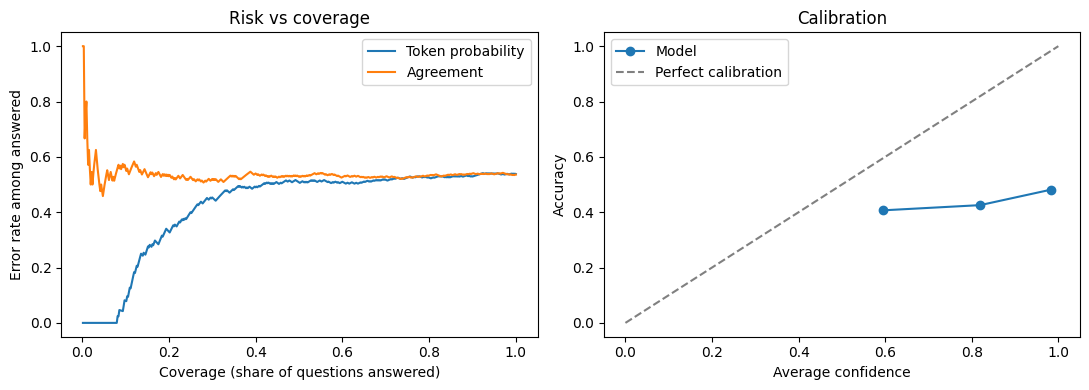

Answer 100% most confident -> error rate 53.8%
Answer 80% most confident -> error rate 52.5%
Answer 60% most confident -> error rate 51.0%


In [23]:
# Risk vs coverage: answer only the most confident questions, withhold the rest
def risk_coverage(conf, wrong):
    order = np.argsort(-conf.values)
    w = wrong.values[order]
    n = np.arange(1, len(w) + 1)
    return n / len(w), np.cumsum(w) / n

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, conf, wrong in [("Token probability", df.token_conf, df.greedy_wrong),
                          ("Agreement", df.agreement_conf, df.majority_wrong)]:
    cov, risk = risk_coverage(conf, wrong)
    ax[0].plot(cov, risk, label=name)
ax[0].set_xlabel("Coverage (share of questions answered)")
ax[0].set_ylabel("Error rate among answered")
ax[0].set_title("Risk vs coverage"); ax[0].legend()

ax[1].plot(table.avg_confidence, table.accuracy, "o-", label="Model")
ax[1].plot([0, 1], [0, 1], "--", color="grey", label="Perfect calibration")
ax[1].set_xlabel("Average confidence"); ax[1].set_ylabel("Accuracy")
ax[1].set_title("Calibration"); ax[1].legend()
plt.tight_layout(); plt.savefig("pilot_plots.png", dpi=150); plt.show()

for c in [1.0, 0.8, 0.6]:
    cov, risk = risk_coverage(df.token_conf, df.greedy_wrong)
    k = int(c * len(df)) - 1
    print(f"Answer {c:.0%} most confident -> error rate {risk[k]:.1%}")

In [24]:
# The dangerous cases: confident AND wrong
cw = df[(df.greedy_wrong == 1)].sort_values("token_conf", ascending=False).head(5)
for _, r in cw.iterrows():
    print(f"[{r.token_conf:.0%} sure] said {r.greedy_answer}, correct {r.gold}: {r.question}")

[100% sure] said maybe, correct no: Ovarian torsion in children: is oophorectomy necessary?
[100% sure] said maybe, correct no: Chemoradiotherapy in the management of locally advanced squamous cell carcinoma esophagus: is surgical resection required?
[100% sure] said maybe, correct no: Totally implantable venous access device placement by interventional radiologists: are prophylactic antibiotics necessary?
[100% sure] said maybe, correct yes: Do patients with rheumatoid arthritis established on methotrexate and folic acid 5 mg daily need to continue folic acid supplements long term?
[100% sure] said yes, correct no: Should temperature be monitorized during kidney allograft preservation?


In [26]:
# How often the model gave each answer (majority of 10 samples), compared with the correct answer
print(pd.crosstab(df.gold, df.majority_answer, margins=True))
print("Unreadable answers:", df.samples.str.count("other").sum())

majority_answer  maybe  no  yes  All
gold                                
maybe               32   1    7   40
no                 121  37   10  168
yes                126   3  163  292
All                279  41  180  500
Unreadable answers: 0


## 7. Summary of results

On 500 PubMedQA questions, Qwen2.5-7B-Instruct (4-bit) was correct 46% of the time.

- When it committed to yes or no, it was right 90% of the time (199 of 222).
- It answered "maybe" 278 times when only 40 questions needed it, and only 32 of those were correct.
- Low confidence did not reliably pick out wrong answers: AUROC 0.58 (token probability) and 0.51 (agreement).
- Answers it was over 90% sure of were correct only 48% of the time.
- Only the 40 most confident answers (8%) were all correct; after that the error rate rose quickly to about 54%.

**Takeaway:** the model's own confidence is not enough to flag its errors, which motivates a check against the retrieved evidence (RQ2 of the proposal).

**Limits:** one model, one prompt, 4-bit compression. Next step: compare other models and prompts.